# Statistics 8: Regression and correlation

*Learning path: probability and statistics, part 8 of 8.* [Index](README.md) · Previous: [Hypothesis tests](07-hypothesis-tests.ipynb)

In 1929 Edwin Hubble plotted, for 24 galaxies, their distance against the speed at which they move away from us. The
points scattered widely, but they rose: the farther the galaxy, the faster it recedes. Hubble drew a straight line
through them, and its slope, now called the Hubble constant, was the first measurement of the expansion of the
universe. This lesson is about that line: how to fit it, how to measure how well it fits, and how a single number,
the **correlation**, can mislead when we forget to look at the picture.

**Who this is for.** You have done lessons 1 to 7. You need the mean and standard deviation, and the equation of a
straight line $y = a + bx$.

**What you will be able to do afterwards:**

1. draw a scatter plot and compute the covariance and the correlation coefficient $r$;
2. fit a least-squares line with `linfit` and interpret its slope, intercept and $r^2$;
3. check a fit with residuals, and recognize when a line is the wrong model (Anscombe's quartet);
4. explain regression to the mean, and why correlation is not causation.

Plan about an hour.

## 1. Scatter plots and correlation

Hubble's data: distance $r$ in megaparsecs (one megaparsec is about 3.3 million light years) and velocity $v$ in km/s,
negative for the few nearby galaxies moving towards us.

24

> `numel` (see `tally`): tally lists the distinct values (first row) and how often each occurs (second row); sort sorts; numel counts; cumsum gives running totals.

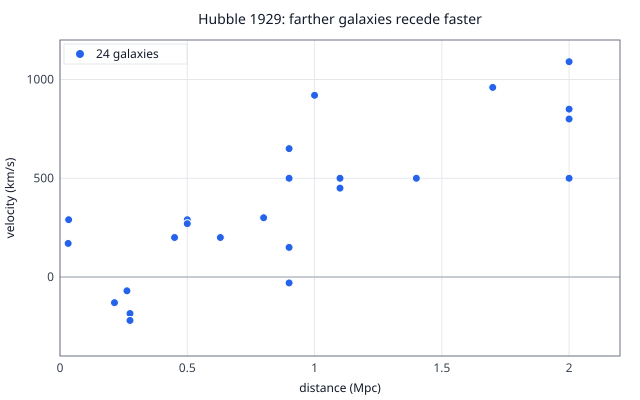

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
r = [0.032 0.034 0.214 0.263 0.275 0.275 0.45 0.5 0.5 0.63 0.8 0.9 0.9 0.9 0.9 1.0 1.1 1.1 1.4 1.7 2.0 2.0 2.0 2.0];
v = [170 290 -130 -70 -185 -220 200 290 270 200 300 -30 650 150 500 920 450 500 500 960 500 850 800 1090];
numel(r)
p = window(scatter(r, v), 0, 2.2, -400, 1200);
labels(title(legend(p, "24 galaxies"), "Hubble 1929: farther galaxies recede faster"), "distance (Mpc)", "velocity (km/s)")

The **covariance** averages the products of deviations from the means, $(x_i - \bar x)(y_i - \bar y)$: it is positive
when large $x$ go with large $y$. Its size depends on the units, so we divide by both standard deviations and get the
**correlation coefficient**

$$r = \frac{\operatorname{cov}(x, y)}{s_x s_y}, \qquad -1 \le r \le 1.$$

In [2]:
cov(r, v)
corr(r, v)

6963731/36800

> Sample covariance: the sum of (x − mean x)(y − mean y) divided by n − 1. Positive when x and y tend to be large together.

6963731/(1443*sqrt(37350257))

> Correlation coefficient r = cov(x, y)/(std(x) std(y)), between −1 and 1: ±1 for points exactly on a line, near 0 for no linear relation. r² = 48493549440361/77772535287993 is the fraction of the variance of y explained by a straight line.

$r = 0.79$: a strong positive relation. $r = \pm 1$ only when the points lie exactly on a line, and $r$ near 0 means
no linear relation (but possibly a curved one, as section 4 shows).

**Try this.** Compute `corr(v, r)`. Does the order matter? And `corr(r, 2*v + 100)`?

## 2. The least-squares line

Which line fits best? The **least-squares** line $y = a + bx$ makes the sum of squared vertical distances from the
points to the line as small as possible. Setting the derivatives with respect to $a$ and $b$ to zero gives

$$b = \frac{\sum (x_i - \bar x)(y_i - \bar y)}{\sum (x_i - \bar x)^2} = r\,\frac{s_y}{s_x}, \qquad a = \bar y - b\,\bar x.$$

`linfit(x, y)` returns the line as an expression in `x`, ready to plot:

34818655000*x/76666317-3126732170/76666317

> Least-squares line: slope b = Sxy/Sxx = 34818655000/76666317, intercept a = mean(y) − b·mean(x) = -3126732170/76666317. It minimizes the sum of squared vertical distances. r² = 48493549440361/77772535287993: the fraction of the variance of y that the line explains.

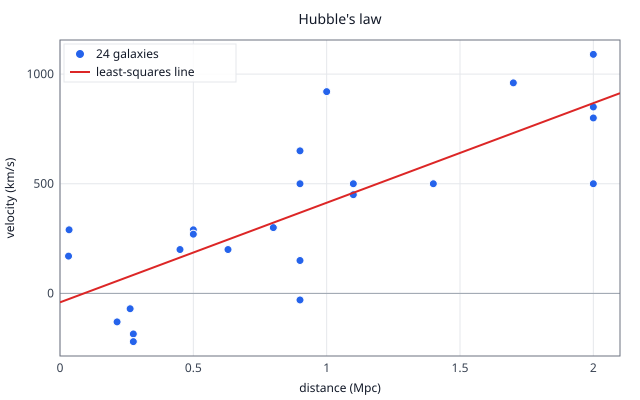

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
fit = linfit(r, v)
p = scatter(r, v);
p = show(p, plot(fit, x, 0, 2.1));
p = legend(p, "24 galaxies", "least-squares line");
labels(title(p, "Hubble's law"), "distance (Mpc)", "velocity (km/s)")

The slope is 454 km/s per megaparsec: Hubble's constant from his own data. (He reported about 500.) Its inverse is a
time: if every galaxy had always moved at its present speed, they were all together $1/H_0$ ago:

In [4]:
eval(3.086e19/454/3.156e16)

2.1537886020893007

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

That is about 2.2 billion years (3.086 × 10¹⁹ km in a megaparsec, 3.156 × 10¹⁶ seconds in a billion years), less
than the age of the Earth from geology, a contradiction that troubled astronomy for decades. Hubble's distances were
too small by a factor of about 7. The modern value, about 70 km/s per megaparsec, gives roughly 14 billion years.

**Try this.** Check the slope formula: compute `eval(corr(r, v)*std(v)/std(r))`.

## 3. Residuals and $r^2$

The **residuals** are the vertical distances from the points to the line, $y_i - (a + b x_i)$. `subs(fit, x, r)`
evaluates the line at every distance:

0.0

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

228.0

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

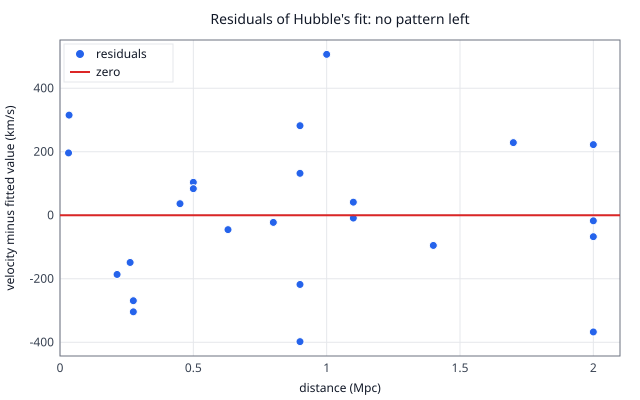

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
res = v - subs(fit, x, r);
round(mean(res), 2)
round(std(res), 0)
p = scatter(r, res);
p = show(p, plot(0, x, 0, 2.1));
p = legend(p, "residuals", "zero");
labels(title(p, "Residuals of Hubble's fit: no pattern left"), "distance (Mpc)", "velocity minus fitted value (km/s)")

The residuals average 0 (least squares guarantees it) and scatter by about 230 km/s without a visible pattern: the
line has taken out the trend, and what remains looks like noise. The note of `linfit` reports $r^2 = 0.62$, the
fraction of the variance of $v$ explained by the line. The other 38% are the residuals: measurement errors and the
galaxies' own motions.

**Try this.** Compute `var(res)/var(v)`. How does it relate to $r^2$?

## 4. Anscombe's quartet: always look

In 1973 Francis Anscombe made four small data sets with the same means, the same correlation and the same fitted line:

In [6]:
x1 = [10 8 13 9 11 14 6 4 12 7 5];
y1 = [8.04 6.95 7.58 8.81 8.33 9.96 7.24 4.26 10.84 4.82 5.68];
y2 = [9.14 8.14 8.74 8.77 9.26 8.10 6.13 3.10 9.13 7.26 4.74];
y3 = [7.46 6.77 12.74 7.11 7.81 8.84 6.08 5.39 8.15 6.42 5.73];
x4 = [8 8 8 8 8 8 8 19 8 8 8];
y4 = [6.58 5.76 7.71 8.84 8.47 7.04 5.25 12.50 5.56 7.91 6.89];
round([mean(y1), mean(y2), mean(y3), mean(y4)], 2)
round([corr(x1, y1), corr(x1, y2), corr(x1, y3), corr(x4, y4)], 3)
[linfit(x1, y1), linfit(x1, y2), linfit(x1, y3), linfit(x4, y4)]

[7.5, 7.5, 7.5, 7.5]

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

[0.816, 0.816, 0.816, 0.817]

> `round` (see `floor`): Round down, up, or to the nearest whole number; round(x, d) keeps d decimals.

[5501*x/11000+33001/11000, 0.5*x+3301/1100, 5497*x/11000+33027/11000, 5499*x/11000+33019/11000]

> Least-squares line: slope b = Sxy/Sxx = 5501/11000, intercept a = mean(y) − b·mean(x) = 33001/11000. It minimizes the sum of squared vertical distances. r² = 30261001/45399960: the fraction of the variance of y that the line explains.
>
> Least-squares line: slope b = Sxy/Sxx = 1/2, intercept a = mean(y) − b·mean(x) = 3301/1100. It minimizes the sum of squared vertical distances. r² = 378125/567549: the fraction of the variance of y that the line explains.
>
> Least-squares line: slope b = Sxy/Sxx = 5497/11000, intercept a = mean(y) − b·mean(x) = 33027/11000. It minimizes the sum of squared vertical distances. r² = 30217009/45348820: the fraction of the variance of y that the line explains.
>
> Least-squares line: slope b = Sxy/Sxx = 5499/11000, intercept a = mean(y) − b·mean(x) = 33019/11000. It minimizes the sum of squared vertical distances. r² = 10079667/15118580: the fraction of the variance of y that the line explains.

All four have mean 7.5, correlation 0.816 and line $y \approx 3 + x/2$. The pictures could hardly be more different:

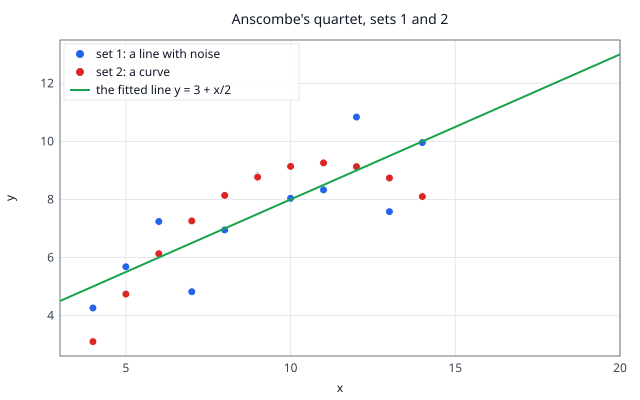

> `labels` (see `title`): A copy of plot p with a title or axis labels.

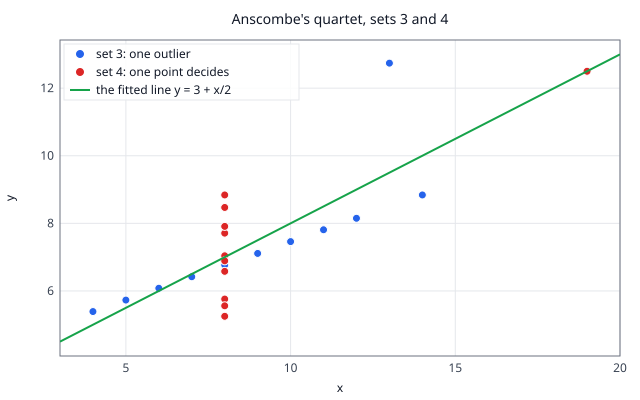

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
p = scatter(x1, y1);
p = show(p, scatter(x1, y2));
p = show(p, plot(3 + x/2, x, 3, 20));
p = legend(p, "set 1: a line with noise", "set 2: a curve", "the fitted line y = 3 + x/2");
labels(title(p, "Anscombe's quartet, sets 1 and 2"), "x", "y")
p = scatter(x1, y3);
p = show(p, scatter(x4, y4));
p = show(p, plot(3 + x/2, x, 3, 20));
p = legend(p, "set 3: one outlier", "set 4: one point decides", "the fitted line y = 3 + x/2");
labels(title(p, "Anscombe's quartet, sets 3 and 4"), "x", "y")

Set 1 is what the numbers suggest. Set 2 is a smooth curve, for which a line is the wrong model. In set 3 a single
outlier pulls the line away from ten points that lie exactly on another line. In set 4 the "relation" rests on one
point: remove it and $x$ does not vary at all. **Plot the data before trusting any summary.**

**Try this.** Remove the outlier from set 3 (the third point) and fit again:
`linfit([10 8 9 11 14 6 4 12 7 5], [7.46 6.77 7.11 7.81 8.84 6.08 5.39 8.15 6.42 5.73])`.

## 5. Regression to the mean, and causation

Francis Galton, who invented the word "regression", noticed in 1886 that very tall parents tend to have children who
are tall, but less extremely so. Simulate 500 fathers and sons in which a son inherits half of his father's distance
from the average, plus independent variation:

0.5186908790460821*x+84.45385069750814

> Least-squares line: slope b = Sxy/Sxx = 0.5186908790460821, intercept a = mean(y) − b·mean(x) = 84.45385069750814. It minimizes the sum of squared vertical distances. r² = 0.2507093106176475: the fraction of the variance of y that the line explains.

0.500708808208571

> Correlation coefficient r = cov(x, y)/(std(x) std(y)), between −1 and 1: ±1 for points exactly on a line, near 0 for no linear relation. r² = 0.25070931061764756 is the fraction of the variance of y explained by a straight line.

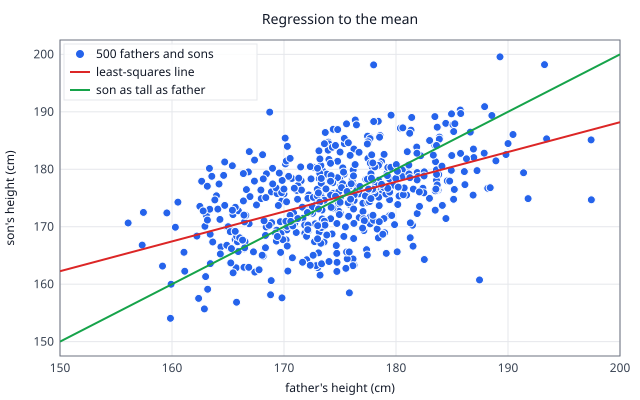

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
seed(1886);
f = 175 + 7*randn(1, 500);
s = 175 + 0.5*(f - 175) + 6*randn(1, 500);
linfit(f, s)
corr(f, s)
p = scatter(f, s);
p = show(p, plot(linfit(f, s), x, 150, 200));
p = show(p, plot(x, x, 150, 200));
p = legend(p, "500 fathers and sons", "least-squares line", "son as tall as father");
labels(title(p, "Regression to the mean"), "father's height (cm)", "son's height (cm)")

The fitted slope is 0.52, less than 1: a father 14 cm above average has sons on average only about 7 cm above
average. Nothing pulls the sons down; the slope is below 1 because the correlation is. The same effect makes the best
performers of one season look worse the next, and makes any treatment given to people "at their worst" look
effective. Comparing with a control group, as the aspirin trial of [lesson 7](07-hypothesis-tests.ipynb) did, is the
cure.

Correlation also does not show **causation**. Ice-cream sales and drownings are correlated because both rise in hot
weather. Only an experiment, in which the treatment is assigned at random, separates cause from coincidence.

**Try this.** Fit the line the other way round, `linfit(s, f)`. Do sons' heights also "regress" when predicting
fathers?

## Summary

* A scatter plot shows the relation; the correlation $r = \operatorname{cov}(x, y)/(s_x s_y)$ measures its linear
  strength, between $-1$ and $1$.
* The least-squares line has slope $b = r\,s_y/s_x$ and passes through $(\bar x, \bar y)$; `linfit` gives it, and
  $r^2$ is the fraction of the variance explained.
* Residuals should look like patternless noise; plot them, and plot the data (Anscombe).
* Regression to the mean comes from $|r| < 1$; correlation is not causation, and randomized experiments are the way to
  causes.

This completes the probability and statistics path. [Back to the index](README.md).

## Exercises

1. **By hand.** For the points $(1, 2), (2, 4), (3, 5), (4, 8)$ compute the slope and intercept of the least-squares
   line with the formulas, then check with `linfit([1 2 3 4], [2 4 5 8])`.
2. **Through the origin.** Hubble's law says $v = H_0 r$ with no intercept. The least-squares slope through the origin
   is $\sum r_i v_i / \sum r_i^2$. Compute it with `(r*v')/(r*r')`.
3. **Units.** If the distances were in light years instead of megaparsecs, what would happen to $r$, to the slope, and
   to $r^2$?
4. **A curved relation.** Let `t = [1 2 3 4 5 6 7 8]` and `y = [2.7 7.4 20.1 54.6 148.4 403.4 1096.6 2981.0]`. Fit a
   line to `y`, then to `log(y)`. Which fits better?
5. **Spurious correlation.** Generate two unrelated running sums, `cumsum(randn(1, 100))` twice, and compute their
   correlation for a few seeds. Why is it often far from 0?

## Hints and answers

* **Section 1, Try this.** The same 0.79; the correlation does not change under $y \to 2y + 100$.
* **Section 2, Try this.** The same slope, 454.16.
* **Section 3, Try this.** 0.376, which is $1 - r^2$: the fraction of the variance the line leaves unexplained.
* **Section 4, Try this.** The ten remaining points lie on a line with slope about 0.35.
* **Section 5, Try this.** Yes: the slope is again about 0.5. Regression to the mean works in both directions.
* **Exercise 1.** $b = 19/10$, $a = 0$.
* **Exercise 2.** About 423 km/s per megaparsec.
* **Exercise 3.** $r$ and $r^2$ do not change; the slope is divided by the number of light years in a megaparsec.
* **Exercise 4.** The values are $e^t$: `linfit(t, log(y))` gives a slope of 1 with $r^2 \approx 1$.
* **Exercise 5.** Running sums wander, and two wandering paths often drift in the same or opposite directions for long
  stretches. Correlation measures a linear association in the sample, not a connection.

## Sources

1. E. Hubble, "A relation between distance and radial velocity among extra-galactic nebulae", *Proceedings of the
   National Academy of Sciences* 15 (1929) 168–173.
2. F. J. Anscombe, "Graphs in statistical analysis", *The American Statistician* 27 (1973) 17–21.
3. F. Galton, "Regression towards mediocrity in hereditary stature", *Journal of the Anthropological Institute* 15
   (1886) 246–263.
4. D. Freedman, R. Pisani and R. Purves, *Statistics*, 4th ed., Norton (2007), chapters 8 to 12.